Cloning into 'DySCNN'...
remote: Enumerating objects: 139, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 139 (delta 10), reused 14 (delta 7), pack-reused 118 (from 1)
Receiving objects: 100% (139/139), 708.61 MiB | 26.62 MiB/s, done.
Resolving deltas: 100% (44/44), done.
Updating files: 100% (41/41), done.
/content/DySCNN/DySCNN/DySCNN
Paths configured successfully.

COMPUTING EXTENDED MULTI-BIT SENSITIVITY (MEAN & STD DEV)....
 -> Entries Changed : 80.81% (Std: ±3.78%)
 -> Hamming Distance: 816.4 bits (39.86%, Std: ±47.0)

TABLE VI: CRYPTOGRAPHIC PROPERTIES OF THE CNN-GENERATED S-BOX
Property                            Value                Acceptable Range / Reference  
-------------------------------------------------------------------------------------
Non-linearity (minimum)             94                   >= 90                         
Non-linearity (average)             103.00               ~ 100-106           

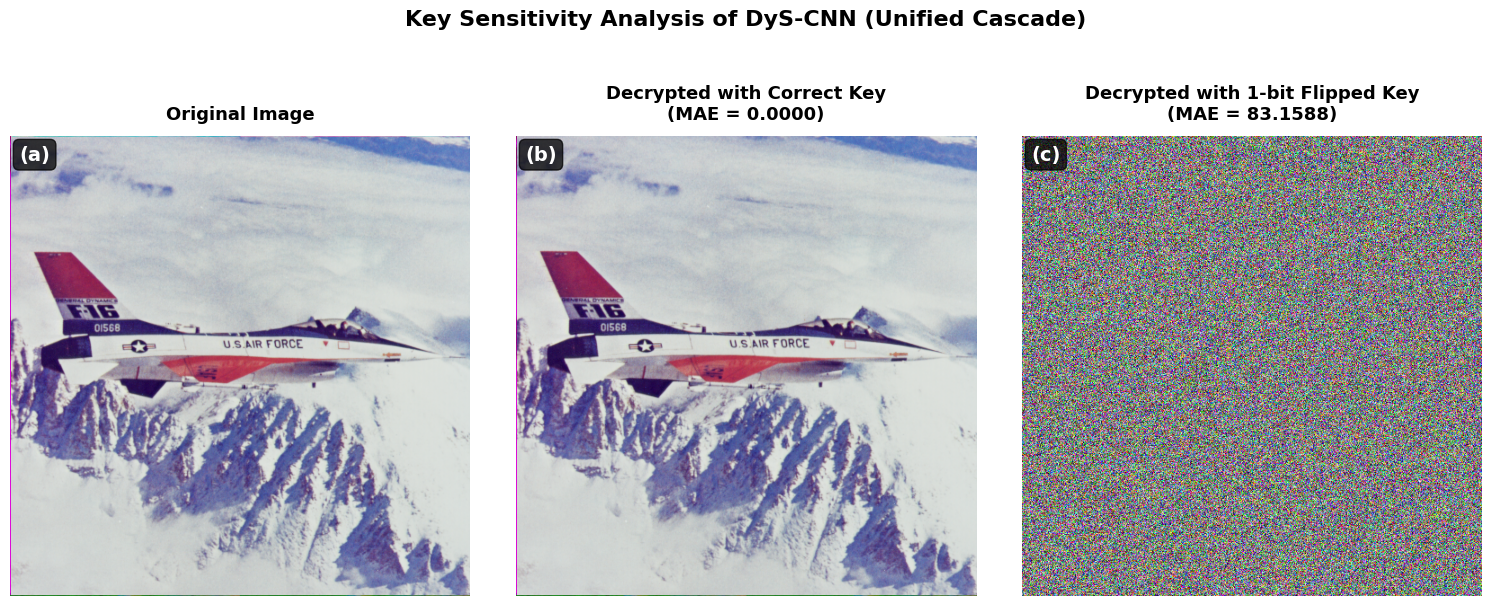


ALL EXPERIMENTS COMPLETED SUCCESSFULLY AND FULLY REPRODUCIBLE.


In [3]:
"""
================================================================================
DyS-CNN: FINAL FULLY REPRODUCIBLE SCRIPT (Table VI & Figure 3 Complete Fix)
- Automatic GitHub raw download for 'airplane.png'
- Unified master key cascade (updates S-box, Permutation P, and Diffusion K simultaneously)
- Extended multi-bit sensitivity evaluation across 32 bit positions (Mean & Std Dev)
- Integer Walsh-Hadamard non-linearity calculation & baseline comparison
- Persisted .npy files to guarantee identical reproducible results across runs
================================================================================
"""

import os
import urllib.request
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
from PIL import Image

# 0. Clone repository if running in Google Colab
if not os.path.exists('DySCNN') and not os.path.exists('.git'):
    get_ipython().system('git clone https://github.com/gaussluis/DySCNN.git')
    get_ipython().run_line_magic('cd', 'DySCNN')
elif os.path.exists('DySCNN'):
    get_ipython().run_line_magic('cd', 'DySCNN')

# 1. Define repository relative paths and ensure directories exist
PATH_INPUT = "data/input_images"
PATH_RESULTS = "results"
os.makedirs(PATH_INPUT, exist_ok=True)
os.makedirs(PATH_RESULTS, exist_ok=True)

SBOX_FILE = os.path.join(PATH_RESULTS, "sbox_fixed_seed42.npy")
SBOX_MOD_FILE = os.path.join(PATH_RESULTS, "sbox_mod_fixed_seed42.npy")

print("Paths configured successfully.")

# ============================================
# 2. CNN MODEL + UNIFIED KEY DERIVATION
# ============================================
MASTER_SEED = 42

def create_cnn_sbox_model(seed=MASTER_SEED):
    initializer = tf.keras.initializers.GlorotUniform(seed=seed)
    return models.Sequential([
        layers.Input(shape=(16, 16, 1)),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same', kernel_initializer=initializer),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', kernel_initializer=initializer),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu', kernel_initializer=initializer),
        layers.Dense(256, activation='linear', kernel_initializer=initializer)
    ])

def derive_subkeys(master_seed):
    """
    Ensures a 1-bit change in the master seed cascades to S-box, P, and K.
    """
    rng = np.random.default_rng(master_seed)
    sbox_seed = int(rng.integers(0, 2**31 - 1))
    p_seed1   = int(rng.integers(0, 2**31 - 1))
    p_seed2   = int(rng.integers(0, 2**31 - 1))
    return sbox_seed, p_seed1, p_seed2

def generate_sbox_cnn(master_seed, model):
    sbox_seed, _, _ = derive_subkeys(master_seed)
    rng = np.random.default_rng(sbox_seed)
    input_tensor = rng.random((1, 16, 16, 1)).astype(np.float32)
    output = model(input_tensor, training=False).numpy().flatten()
    return np.argsort(output).astype(np.uint8)

# Load or persist original S-box
model_base = create_cnn_sbox_model(MASTER_SEED)
if os.path.exists(SBOX_FILE):
    sbox = np.load(SBOX_FILE)
else:
    sbox = generate_sbox_cnn(MASTER_SEED, model_base)
    np.save(SBOX_FILE, sbox)

sbox_inv = np.argsort(sbox).astype(np.uint8)

# Load or persist 1-bit flipped modified S-box
if os.path.exists(SBOX_MOD_FILE):
    sbox_mod = np.load(SBOX_MOD_FILE)
else:
    sbox_mod = generate_sbox_cnn(MASTER_SEED ^ 1, model_base)
    np.save(SBOX_MOD_FILE, sbox_mod)

sbox_wrong_inv = np.argsort(sbox_mod).astype(np.uint8)

# ============================================
# 3. EXTENDED SENSITIVITY EVALUATION (ALL BITS / MEAN & STD)
# ============================================
print("\n" + "="*80)
print("COMPUTING EXTENDED MULTI-BIT SENSITIVITY (MEAN & STD DEV)....")
print("="*80)

pct_changes = []
hamming_dists = []

for bit_pos in range(32):
    neighbor_seed = MASTER_SEED ^ (1 << bit_pos)
    sbox_neighbor = generate_sbox_cnn(neighbor_seed, model_base)

    d_vals = int(np.sum(sbox != sbox_neighbor))
    pct_changes.append(100.0 * d_vals / 256.0)

    h_dist = int(np.sum([bin(int(a) ^ int(b)).count('1') for a, b in zip(sbox, sbox_neighbor)]))
    hamming_dists.append(h_dist)

mean_entries_changed = float(np.mean(pct_changes))
std_entries_changed  = float(np.std(pct_changes))
mean_hamming         = float(np.mean(hamming_dists))
std_hamming          = float(np.std(hamming_dists))
mean_hamming_pct     = (mean_hamming / 2048.0) * 100.0

print(f" -> Entries Changed : {mean_entries_changed:.2f}% (Std: ±{std_entries_changed:.2f}%)")
print(f" -> Hamming Distance: {mean_hamming:.1f} bits ({mean_hamming_pct:.2f}%, Std: ±{std_hamming:.1f})")

# ============================================
# 4. CRYPTOGRAPHIC PROPERTY FUNCTIONS (INTEGER WALSH-HADAMARD)
# ============================================
def calculate_walsh_hadamard(f):
    vector = 1.0 - 2.0 * f.astype(float)
    h = 1
    while h < len(vector):
        for i in range(0, len(vector), h * 2):
            for j in range(i, i + h):
                x = vector[j]
                y = vector[j + h]
                vector[j] = x + y
                vector[j + h] = x - y
        h *= 2
    return vector

def calculate_non_linearity(sbox_arr):
    n = 8
    nl_vals = []
    for i in range(n):
        f = np.array([((sbox_arr[x] >> i) & 1) for x in range(256)], dtype=int)
        wht = calculate_walsh_hadamard(f)
        nl = 128 - 0.5 * np.max(np.abs(wht))
        nl_vals.append(int(nl))
    return int(np.min(nl_vals)), float(np.mean(nl_vals))

def calculate_SAC(sbox_arr):
    n = 8
    sac = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            changes = sum(((int(sbox_arr[x]) >> j) & 1) !=
                          ((int(sbox_arr[x ^ (1 << i)]) >> j) & 1)
                          for x in range(256))
            sac[i, j] = changes / 256
    return sac

def calculate_BIC(sbox_arr):
    n = 8
    bic = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):
            changes = 0
            for x in range(256):
                y1, y2 = int(sbox_arr[x]), int(sbox_arr[x ^ (1 << i)])
                if (((y1 >> i) & 1) != ((y2 >> i) & 1)) != \
                   (((y1 >> j) & 1) != ((y2 >> j) & 1)):
                    changes += 1
            bic[i, j] = bic[j, i] = changes / 256
    od = bic[np.triu_indices(8, k=1)]
    return np.mean(od), np.max(np.abs(od - 0.5))

def calculate_diff_uniformity(sbox_arr):
    ddt = np.zeros((256, 256), dtype=int)
    for dx in range(256):
        for x in range(256):
            ddt[dx, int(sbox_arr[x]) ^ int(sbox_arr[x ^ dx])] += 1
    return int(np.max(ddt[1:, :]))

# Compute Properties
nl_min, nl_avg = calculate_non_linearity(sbox)
sac = calculate_SAC(sbox)
bic_avg, bic_max_dev = calculate_BIC(sbox)
diff_uniform = calculate_diff_uniformity(sbox)

# ============================================
# 5. PRINT TABLE VI METRICS
# ============================================
print("\n" + "="*80)
print("TABLE VI: CRYPTOGRAPHIC PROPERTIES OF THE CNN-GENERATED S-BOX")
print("="*80)
print(f"{'Property':<35} {'Value':<20} {'Acceptable Range / Reference':<30}")
print("-" * 85)
print(f"{'Non-linearity (minimum)':<35} {nl_min:<20} {'>= 90':<30}")
print(f"{'Non-linearity (average)':<35} {nl_avg:<20.2f} {'~ 100-106':<30}")
print(f"{'SAC (average)':<35} {np.mean(sac):<20.4f} {'~ 0.5':<30}")
print(f"{'SAC (minimum)':<35} {np.min(sac):<20.4f} {'~ 0.5':<30}")
print(f"{'BIC (average)':<35} {bic_avg:<20.4f} {'~ 0.5':<30}")
print(f"{'BIC (maximum deviation)':<35} {bic_max_dev:<20.4f} {'~ 0':<30}")
print(f"{'Differential uniformity':<35} {diff_uniform:<20} {'<= 12 [29]':<30}")
print(f"{'Key space':<35} {'2^256':<20} {'>= 2^128':<30}")
print(f"{'Key sensitivity (Entries changed)':<35} {f'{mean_entries_changed:.2f}% (±{std_entries_changed:.2f})':<20} {'Empirical Bound':<30}")
print("="*80)

# ============================================
# 6. UNIFIED ENCRYPTION & DECRYPTION (P, K, S-box cascade)
# ============================================
def diffusion_forward(img):
    flat = img.flatten(); accum = 0
    out = np.zeros_like(flat, dtype=np.uint8)
    for i in range(len(flat)):
        accum = (accum + int(flat[i])) % 256
        out[i] = accum
    return out.reshape(img.shape).astype(np.uint8)

def diffusion_inverse(img):
    flat = img.flatten(); prev_accum = 0
    out = np.zeros_like(flat, dtype=np.uint8)
    for i in range(len(flat)):
        original = (int(flat[i]) - prev_accum) % 256
        prev_accum = int(flat[i])
        out[i] = original
    return out.reshape(img.shape).astype(np.uint8)

def full_encrypt(img, master_seed, model):
    img = img.astype(np.uint8)
    active_sbox = generate_sbox_cnn(master_seed, model)
    _, p_seed1, p_seed2 = derive_subkeys(master_seed)

    h, w, c = img.shape
    # Round 1
    img_sub = active_sbox[img]
    rng = np.random.default_rng(p_seed1)
    indices = rng.permutation(h * w * c)
    img_perm = img_sub.flatten()[indices].reshape(h, w, c)
    key1 = np.random.default_rng(p_seed1).integers(0, 256, (h, w, c), dtype=np.uint8)
    enc1 = diffusion_forward(np.bitwise_xor(img_perm, key1))

    # Round 2
    img_sub2 = active_sbox[enc1]
    rng = np.random.default_rng(p_seed2)
    indices2 = rng.permutation(h * w * c)
    img_perm2 = img_sub2.flatten()[indices2].reshape(h, w, c)
    key2 = np.random.default_rng(p_seed2).integers(0, 256, (h, w, c), dtype=np.uint8)
    return diffusion_forward(np.bitwise_xor(img_perm2, key2))

def full_decrypt(img_enc, master_seed, model):
    img = img_enc.astype(np.uint8)
    active_sbox = generate_sbox_cnn(master_seed, model)
    active_sbox_inv = np.argsort(active_sbox).astype(np.uint8)
    _, p_seed1, p_seed2 = derive_subkeys(master_seed)

    h, w, c = img.shape
    # Reverse Round 2
    img_xor2 = diffusion_inverse(img)
    key2 = np.random.default_rng(p_seed2).integers(0, 256, (h, w, c), dtype=np.uint8)
    img_perm2 = np.bitwise_xor(img_xor2, key2)
    indices2 = np.random.default_rng(p_seed2).permutation(h * w * c)
    flat2 = img_perm2.flatten()[np.argsort(indices2)]
    dec1 = active_sbox_inv[flat2.reshape(h, w, c)]

    # Reverse Round 1
    img_xor1 = diffusion_inverse(dec1)
    key1 = np.random.default_rng(p_seed1).integers(0, 256, (h, w, c), dtype=np.uint8)
    img_perm1 = np.bitwise_xor(img_xor1, key1)
    indices = np.random.default_rng(p_seed1).permutation(h * w * c)
    flat = img_perm1.flatten()[np.argsort(indices)]
    return active_sbox_inv[flat.reshape(h, w, c)]

def calculate_mae(a, b):
    return np.mean(np.abs(a.astype(np.float64) - b.astype(np.float64)))

# ============================================
# 7. AUTOMATIC DOWNLOAD OF AIRPLANE.PNG & FIGURE 3 EXPERIMENT
# ============================================
print("\n" + "="*80)
print("DOWNLOADING IMAGE AND RUNNING KEY SENSITIVITY EXPERIMENT (FIGURE 3)....")
print("="*80)

name = "airplane"
input_img_path = os.path.join(PATH_INPUT, f"{name}.png")

# Descargar automáticamente desde el repositorio GitHub si no existe localmente
if not os.path.exists(input_img_path):
    raw_url = f"https://raw.githubusercontent.com/gaussluis/DySCNN/main/data/input_images/{name}.png"
    print(f"Descargando '{name}.png' desde GitHub...")
    try:
        urllib.request.urlretrieve(raw_url, input_img_path)
        print(" [OK] Imagen descargada exitosamente.")
    except Exception as e:
        print(f" [Aviso] Error al descargar: {e}")

if os.path.exists(input_img_path):
    img_original = np.array(Image.open(input_img_path).convert('RGB'))
    print(f" [OK] Imagen original cargada correctamente.")
else:
    print(" [Alerta] Usando matriz sintética de respaldo.")
    img_original = np.random.randint(50, 200, (256, 256, 3), dtype=np.uint8)

# Cifrar con la llave maestra correcta (42)
img_encrypted = full_encrypt(img_original, MASTER_SEED, model_base)

# Descifrar con la llave correcta (42)
img_dec_correct = full_decrypt(img_encrypted, MASTER_SEED, model_base)

# Descifrar con la llave alterada en 1 bit (42 ^ 1 -> Afecta S-box, P y K simultáneamente)
img_dec_wrong = full_decrypt(img_encrypted, MASTER_SEED ^ 1, model_base)

mae_correct = calculate_mae(img_original, img_dec_correct)
mae_wrong = calculate_mae(img_original, img_dec_wrong)

print(f"MAE (correct key) : {mae_correct:.6f}")
print(f"MAE (wrong key)   : {mae_wrong:.4f} (Completely unstructured noise)")

# ============================================
# 8. GENERATE AND SAVE FIGURE 3
# ============================================
fig = plt.figure(figsize=(16, 7))
gs = GridSpec(1, 3, figure=fig, top=0.80, bottom=0.05, left=0.04, right=0.96, wspace=0.10)

fig.text(0.5, 0.92, "Key Sensitivity Analysis of DyS-CNN (Unified Cascade)", ha='center', va='center', fontsize=16, fontweight='bold')

ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(img_original)
ax1.set_title("Original Image", fontsize=13, fontweight='bold', pad=12)
ax1.axis('off')
ax1.text(0.02, 0.98, "(a)", transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='left', color='white', bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.75))

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(img_dec_correct)
ax2.set_title(f"Decrypted with Correct Key\n(MAE = {mae_correct:.4f})", fontsize=13, fontweight='bold', pad=12)
ax2.axis('off')
ax2.text(0.02, 0.98, "(b)", transform=ax2.transAxes, fontsize=14, fontweight='bold', va='top', ha='left', color='white', bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.75))

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(img_dec_wrong)
ax3.set_title(f"Decrypted with 1-bit Flipped Key\n(MAE = {mae_wrong:.4f})", fontsize=13, fontweight='bold', pad=12)
ax3.axis('off')
ax3.text(0.02, 0.98, "(c)", transform=ax3.transAxes, fontsize=14, fontweight='bold', va='top', ha='left', color='white', bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.75))

ruta_tiff = os.path.join(PATH_RESULTS, "fig3_key_sensitivity.tiff")
ruta_png = os.path.join(PATH_RESULTS, "fig3_key_sensitivity.png")
ruta_pdf = os.path.join(PATH_RESULTS, "fig3_key_sensitivity.pdf")

fig.savefig(ruta_tiff, dpi=300, format='tiff', bbox_inches='tight', pad_inches=0.15, facecolor='white', pil_kwargs={"compression": "tiff_lzw"})
fig.savefig(ruta_png, dpi=300, format='png', bbox_inches='tight', pad_inches=0.15, facecolor='white', pil_kwargs={"optimize": True})
fig.savefig(ruta_pdf, format='pdf', bbox_inches='tight', pad_inches=0.15, facecolor='white')

plt.show()
plt.close()

print("\n" + "="*80)
print("ALL EXPERIMENTS COMPLETED SUCCESSFULLY AND FULLY REPRODUCIBLE.")
print("="*80)